# rspd quickstart

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ThatE10/rspd/blob/main/examples/quickstart.ipynb)

SRSPD finds the part of a layer's weights that one behaviour uses and another does not, in closed form, with no training.

This notebook shows it on a toy small enough to see whole. It runs on a CPU in a few seconds and needs no account.

You give it two sets of activations:

- **X**, the *target*: examples of the behaviour you want to isolate or remove.
- **Y**, the *retained* set: examples of behaviour you want left alone.

For a layer with weights `W`, it returns a component `M`. `M` carries what only X uses. `W - M` is the layer with that part taken out.

In [1]:
# Installs rspd when it is missing (on Colab). Nothing happens if it is already installed.
import importlib.util, subprocess, sys

if importlib.util.find_spec("rspd") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "rspd @ git+https://github.com/ThatE10/rspd"])

In [2]:
import matplotlib.pyplot as plt
import torch

import rspd
import rspd.toy

X_COLOR, Y_COLOR, SHARED_COLOR, INK = "#b98a00", "#c43d6f", "#d9772b", "#222222"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## The toy

The input activation space has five directions. X is active on its own two directions and on a shared one. Y is active on the shared one and on its own two.

One linear layer `W` reads this space.

In [3]:
toy = rspd.toy.two_sets(seed=0)

print("W", tuple(toy.W.shape), " X", tuple(toy.X.shape), " Y", tuple(toy.Y.shape))
print("directions:", toy.directions)

W (4, 5)  X (1000, 5)  Y (1000, 5)
directions: ['x0', 'x1', 'shared', 'y0', 'y1']


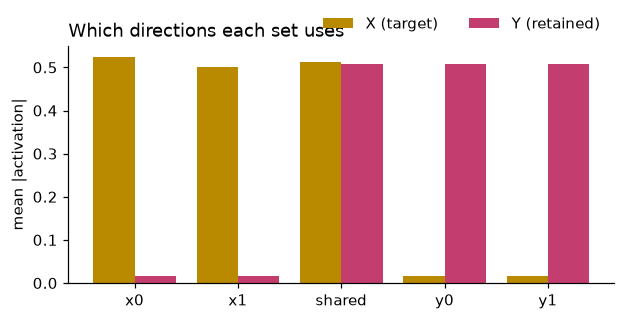

In [4]:
fig, ax = plt.subplots(figsize=(6.4, 2.8))
pos = torch.arange(len(toy.directions))
ax.bar(pos - 0.2, toy.X.abs().mean(0), width=0.4, color=X_COLOR, label="X (target)")
ax.bar(pos + 0.2, toy.Y.abs().mean(0), width=0.4, color=Y_COLOR, label="Y (retained)")
ax.set_xticks(pos, toy.directions)
ax.set_ylabel("mean |activation|")
ax.set_title("Which directions each set uses", loc="left")
ax.legend(frameon=False, ncol=2, loc="lower right", bbox_to_anchor=(1.0, 1.0))
plt.show()

## Fit

One call. The dose `mu_per_token` says how much disturbance of Y you accept per token of X removed: larger takes more of the shared direction.

In [5]:
M = rspd.core.erased_component(toy.W, toy.X, toy.Y, mu=toy.mu(mu_per_token=0.1))

print(type(M).__name__, "with factors A", tuple(M.A.shape), "and B", tuple(M.B.shape))

Component with factors A (4, 1000) and B (1000, 5)


## What the component carries

For each input direction, how much of the layer's output goes through `M`, and how much is left in `W - M`.

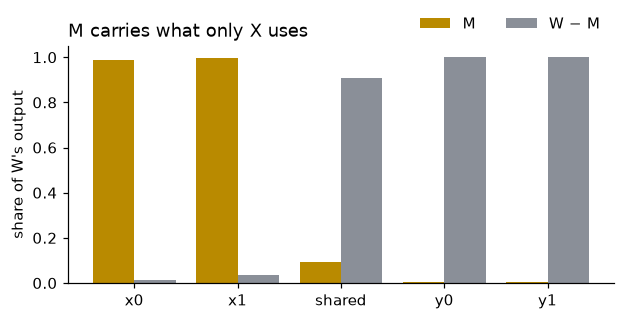

     x0   in M: 0.99   left in W - M: 0.01
     x1   in M: 0.99   left in W - M: 0.03
 shared   in M: 0.09   left in W - M: 0.91
     y0   in M: 0.00   left in W - M: 1.00
     y1   in M: 0.00   left in W - M: 1.00


In [6]:
in_M = rspd.toy.carried(toy.W, M)
in_rest = rspd.toy.carried(toy.W, toy.W - M.dense())

fig, ax = plt.subplots(figsize=(6.4, 2.8))
ax.bar(pos - 0.2, in_M, width=0.4, color=X_COLOR, label="M")
ax.bar(pos + 0.2, in_rest, width=0.4, color="#8a8f98", label="W − M")
ax.set_xticks(pos, toy.directions)
ax.set_ylabel("share of W's output")
ax.set_title("M carries what only X uses", loc="left")
ax.legend(frameon=False, ncol=2, loc="lower right", bbox_to_anchor=(1.0, 1.0))
plt.show()

for name, a, b in zip(toy.directions, in_M, in_rest):
    print(f"{name:>7}   in M: {float(a):.2f}   left in W - M: {float(b):.2f}")

The two X directions go through `M` almost whole. The two Y directions do not go through it at all. The shared direction mostly stays behind, because Y needs it.

## Removing X from the layer

Subtract the component: `W_new = W - M`. The *leaks* say how well that worked.

- `L_X_rel`: the share of the layer's response to X that survives. Lower means more was removed.
- `L_Y_rel`: the share of the layer's response to Y that was disturbed. Lower means Y was better preserved.

In [7]:
W_new = rspd.core.apply_erasure(toy.W, M)
leaks = rspd.core.leaks(toy.W, M, toy.X, toy.Y)

print(f"response to X surviving: {leaks['L_X_rel']:.2f}")
print(f"response to Y disturbed: {leaks['L_Y_rel']:.2f}")

response to X surviving: 0.68
response to Y disturbed: 0.06


Some of the response to X survives on purpose: it is the part that runs along the shared direction, which Y also uses.

## The dose

`mu_per_token` moves the shared direction between the two sides. The X-only and Y-only directions barely move.

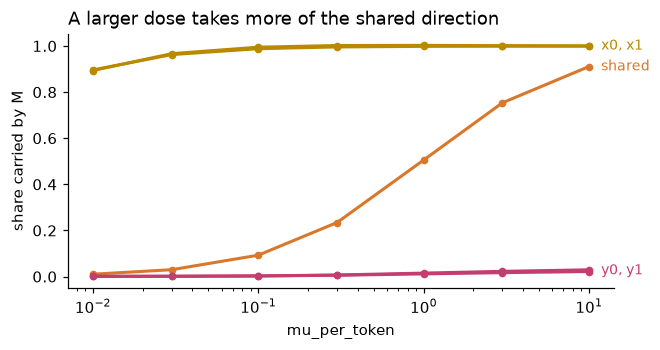

In [8]:
doses = [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0]
rows = torch.stack([rspd.toy.carried(toy.W, rspd.core.erased_component(
    toy.W, toy.X, toy.Y, mu=toy.mu(m))) for m in doses])

fig, ax = plt.subplots(figsize=(6.4, 3.0))
for group, color in (("x", X_COLOR), ("shared", SHARED_COLOR), ("y", Y_COLOR)):
    idx = toy.index(group)
    ax.plot(doses, rows[:, idx], color=color, lw=2, marker="o", ms=4)
    ax.annotate(", ".join(toy.directions[i] for i in idx), (doses[-1], float(rows[-1, idx].mean())),
                xytext=(8, 0), textcoords="offset points", va="center", color=color, fontsize=9)
ax.set_xscale("log")
ax.set_xlabel("mu_per_token")
ax.set_ylabel("share carried by M")
ax.set_title("A larger dose takes more of the shared direction", loc="left")
plt.show()

## The same thing on a model

On a real model the activations come from text, and every attention and MLP projection gets its own component. The call has the same shape:

```python
from transformers import AutoModelForCausalLM, AutoTokenizer
from rspd import SRSPD

model = AutoModelForCausalLM.from_pretrained("gpt2")
tokenizer = AutoTokenizer.from_pretrained("gpt2")

srspd = SRSPD(model, tokenizer)                        # attach
components = srspd.fit(target=dutch, retained=english, mu_per_token=1.0)
components.apply()                                     # W <- W - M, every layer
components.leaks                                       # per matrix
components.restore()                                   # bit-for-bit undo
```

`dutch` and `english` are lists of strings. [`erase_dutch.ipynb`](erase_dutch.ipynb) runs this end to end and removes Dutch from an open 4B model on a free Colab GPU.